# Clustering Voice Dataset Based on Gender

In this notebook, we aim to **cluster a voice dataset** to distinguish between different genders using learning techniques.

## Objectives
- Apply **at least two clustering algorithms** to the dataset.
- Determine the **optimal number of clusters** using the **Silhouette Score**.
- Analyze and compare the performance of the clustering models.

## Key Steps
1. **Data Loading:** Import the final preprocessed dataset.
2. **Exploratory Data Analysis (EDA):** Quick insights into the data distribution.
3. **Modeling:**
   - Apply **K-Means Clustering** and **DBSCAN**.
   - Evaluate each model using the **Silhouette Score** to determine the best number of clusters.


# Imports and Settings

In [180]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

from sklearn.metrics import silhouette_score, pairwise_distances_argmin_min
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.cluster import AgglomerativeClustering
from scipy.spatial.distance import pdist, squareform
from sklearn.metrics.pairwise import euclidean_distances

import numpy as np

# Loading Dataset

In [181]:
df = pd.read_csv('final_dataset.csv')
df["gender"] = df["gender"].map({"male": 1, "female": 0})
excluded_columns = ["question_number",
                    "student_id",
                    "has_intro",
                    "file_name",
                    ]
data = df.copy()
df = df.drop(columns=excluded_columns)

# EDA

## Summary Statistics

 Display descriptive statistics (mean, median, standard deviation) to understand feature distributions.


In [182]:
df.describe()

,zero_crossing_rate,energy,spectral_centroid,spectral_bandwidth,log_mel_1,log_mel_2,log_mel_3,log_mel_4,log_mel_5,log_mel_6,...,mfcc_12,mfcc_13,spectral_contrast_1,spectral_contrast_2,spectral_contrast_3,spectral_contrast_4,spectral_contrast_5,spectral_contrast_6,spectral_contrast_7,gender
count,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,...,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000
mean,0.054954,0.170976,1893.056793,1929.081328,-24.408357,-20.533612,-19.026207,-23.217894,-30.253764,-35.060643,...,-2.817423,-4.180447,17.667740,14.178068,19.442202,19.898673,22.756795,31.342683,31.292369,0.768575
std,0.055693,0.026658,1285.677087,414.365355,11.105592,10.241122,10.655355,11.713222,11.641152,10.884943,...,8.598965,9.469299,3.597710,2.438562,2.943168,2.643634,2.429598,4.304217,6.560196,0.422001
min,0.006679,0.001929,676.703972,1094.504697,-69.511160,-69.631996,-70.493220,-70.769890,-71.311760,-71.659270,...,-32.578854,-30.792100,6.134539,5.500055,7.212382,8.723677,14.126717,15.918311,13.496614,0.000000
25%,0.027361,0.164994,1240.350891,1642.914456,-30.456938,-24.566574,-22.241800,-28.678220,-37.371340,-41.897877,...,-8.758240,-10.399458,15.196449,12.764616,17.941771,18.356203,21.076658,28.461698,27.175248,1.000000
50%,0.035740,0.174484,1482.816332,1859.053958,-22.466913,-18.233969,-15.703797,-21.320694,-29.064032,-34.157158,...,-2.869582,-4.863769,18.348865,14.183379,19.654289,20.060046,22.618777,31.304603,30.850208,1.000000
75%,0.055541,0.184325,1934.814207,2125.475898,-16.285906,-13.515914,-12.299141,-14.575443,-21.959051,-27.073206,...,3.029158,1.903227,20.481872,15.682439,21.421342,21.611011,24.315244,34.211570,35.127551,1.000000
max,0.389508,0.255353,9404.544156,3828.028079,-4.265939,-5.610474,-4.974742,-5.276269,-7.448854,-10.938334,...,24.490343,29.624844,26.220016,22.694689,26.313290,29.945191,31.761034,44.890301,50.992761,1.000000


# Feature selection

As it might come to mind one of the most important steps of running a clustering algorithm is preprocessing a feature selecting 
the features should be selected so that they would mimic the difference between the data point the best way possible 
so the first two steps we took in the previous parts was to denoise and preprocess and then extract features from the raw data we had
now in this part we need to select the best features for the clustering algorithm. one of the needs for the algorithm is that we disclude and drop the features that are highly correlated with each other
also we can analyse the relationship between the gender class and each feature to evaluate the capabilities of each feature in diferentaiting between the voice of a male and a female

c:\Users\Mr. Hajiheideri\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
c:\Users\Mr. Hajiheideri\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
c:\Users\Mr. Hajiheideri\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.


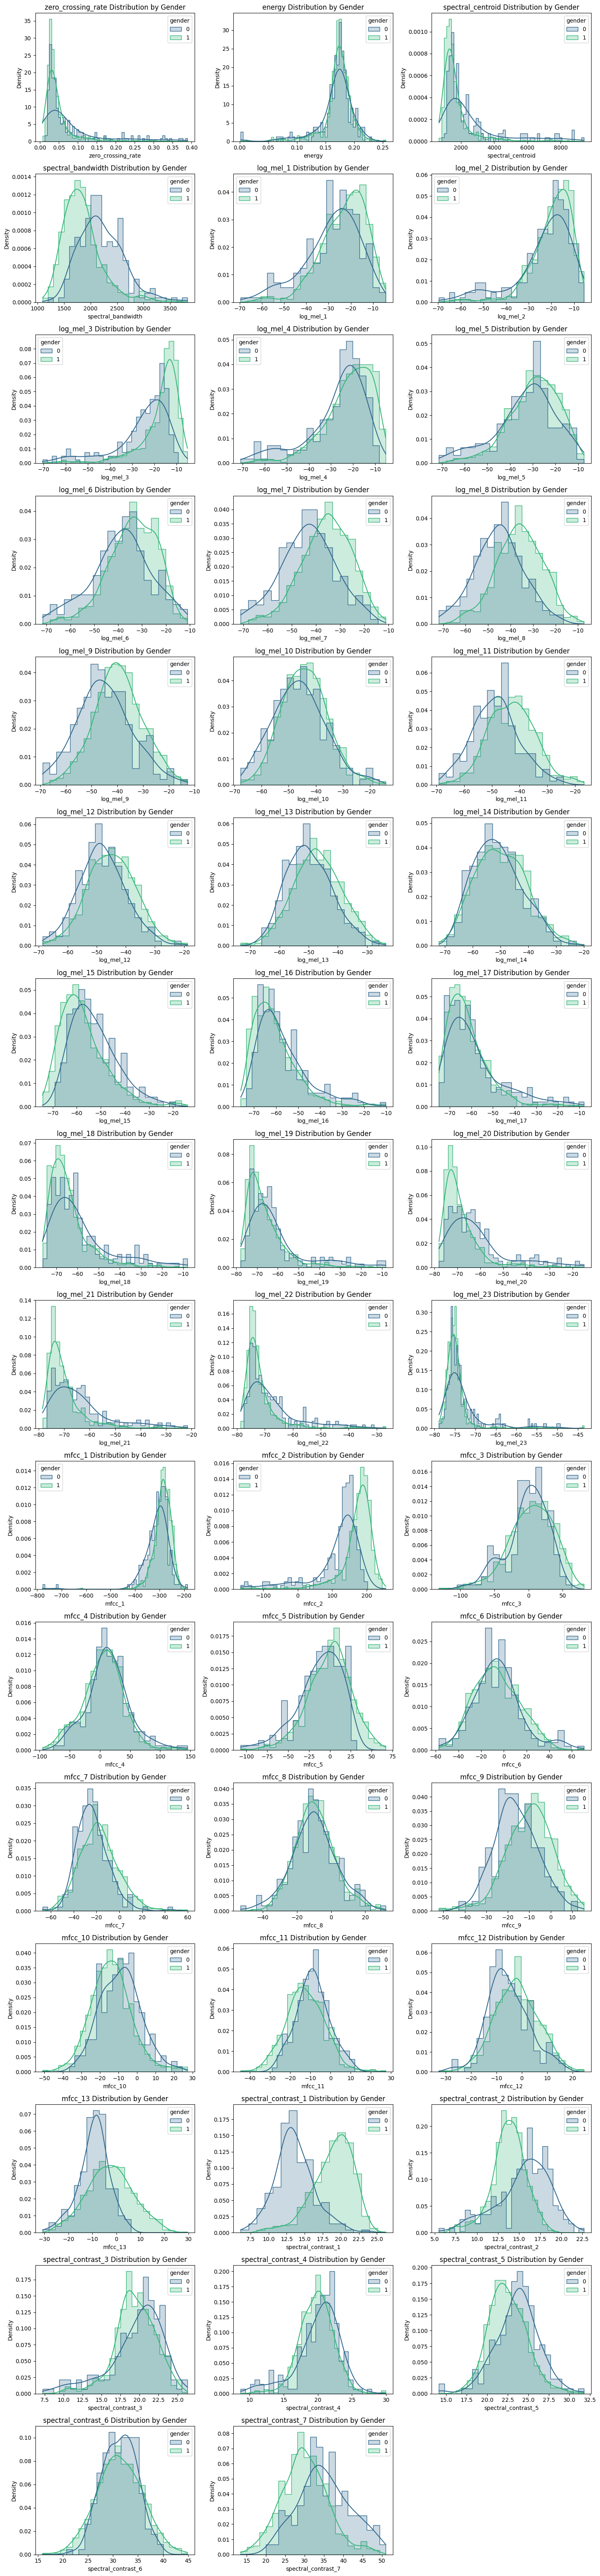

In [183]:


features_to_plot = [col for col in df.columns if col != "gender"]

n_features = len(features_to_plot)
n_cols = 3  
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
axes = axes.flatten() 

for i, feature in enumerate(features_to_plot):
    sns.histplot(
        data=df,
        x=feature,
        hue='gender',
        kde=True,
        ax=axes[i],
        palette="viridis",
        element="step",  
        stat="density",  
        common_norm=False
    )
    axes[i].set_title(f'{feature} Distribution by Gender')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Density")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


as it can be seen the features with more correlation with the gender class can distinguish it better than the rest of the features

In [184]:
def get_corr(data):
    num_cols = data.select_dtypes(include=['int64', 'float64']).columns   
    corr_matrix = data[num_cols].corr()
    upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    high_corr_features = [(column, upper_triangle[column].idxmax(), upper_triangle[column].max()) for column in upper_triangle.columns if any(upper_triangle[column] > 0.9)]
    for feature1, feature2, corr_value in high_corr_features:
        print(f"{feature1} and {feature2} have a correlation of {corr_value}")
    return corr_matrix

now we have calculated the correlation between each two feature now with a threshold of 0.9 we will drop correlated features

In [185]:
corr_matrix = get_corr(df)

spectral_centroid and zero_crossing_rate have a correlation of 0.9881841285515741
log_mel_5 and log_mel_4 have a correlation of 0.9477458535942098
log_mel_6 and log_mel_5 have a correlation of 0.9674627552423725
log_mel_7 and log_mel_6 have a correlation of 0.9574777163616951
log_mel_8 and log_mel_7 have a correlation of 0.9396201015580519
log_mel_12 and log_mel_11 have a correlation of 0.9040652333066013
log_mel_17 and log_mel_16 have a correlation of 0.9333421186799015
log_mel_18 and log_mel_17 have a correlation of 0.9321549391243034
log_mel_19 and log_mel_18 have a correlation of 0.9187302232701716
log_mel_20 and log_mel_19 have a correlation of 0.9418945927958875
log_mel_21 and log_mel_20 have a correlation of 0.962770181023063
log_mel_22 and log_mel_21 have a correlation of 0.9598337652363932


as it can be seen the correlation between the log_mel features is high and a number of them need to be droped

In [186]:
log_mel_features = [col for col in df.columns if "log_mel" in col]
log_mel_data = df[log_mel_features]

scaler = StandardScaler()
log_mel_scaled = scaler.fit_transform(log_mel_data)

pca = PCA(n_components=0.95)
log_mel_pca = pca.fit_transform(log_mel_scaled)

pca_columns = [f"log_mel_pca_{i}" for i in range(log_mel_pca.shape[1])]
df_pca = pd.DataFrame(log_mel_pca, columns=pca_columns)

df = df.drop(columns=log_mel_features)
df.reset_index(drop=True, inplace=True)
df_pca.reset_index(drop=True, inplace=True)
df = pd.concat([df, df_pca], axis=1)

print(f"Original log-mel features: {len(log_mel_features)}, Reduced to: {len(pca_columns)}")

Original log-mel features: 23, Reduced to: 8


In [187]:
df.drop(columns=['zero_crossing_rate', 'log_mel_pca_0'], inplace=True)

In [188]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 821 entries, 0 to 820
Data columns (total 31 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   energy               821 non-null    float64
 1   spectral_centroid    821 non-null    float64
 2   spectral_bandwidth   821 non-null    float64
 3   mfcc_1               821 non-null    float64
 4   mfcc_2               821 non-null    float64
 5   mfcc_3               821 non-null    float64
 6   mfcc_4               821 non-null    float64
 7   mfcc_5               821 non-null    float64
 8   mfcc_6               821 non-null    float64
 9   mfcc_7               821 non-null    float64
 10  mfcc_8               821 non-null    float64
 11  mfcc_9               821 non-null    float64
 12  mfcc_10              821 non-null    float64
 13  mfcc_11              821 non-null    float64
 14  mfcc_12              821 non-null    float64
 15  mfcc_13              821 non-null    flo

now we have 30 features which we could use for the clustering process

# Clustering

Before starting, let's standardize the data.

In [189]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)

Also use PCA for visualizing data

In [190]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(scaled_data)

## KMeans

### Similarity and Dissimilarity

now for the clustering algorithms we are going to use we define a distance measure meaning this metric would calculate the dissimmilarities and the similarities in the data set

In [191]:
def euclidean_distance(a, b):
    return np.linalg.norm(a - b)

def similarity_and_dissimilarity_report(kmeans_model: KMeans):
    centroids = kmeans_model.cluster_centers_
    num_clusters = len(centroids)
    dissimilarity_matrix = euclidean_distances(centroids)
    similarity_matrix = 1 / (1 + dissimilarity_matrix)

    fig, ax = plt.subplots(1, 2, figsize=(12, 6))

    sns.heatmap(dissimilarity_matrix, annot=True, cmap='YlGnBu', ax=ax[0], cbar_kws={'label': 'Euclidean Distance'})
    ax[0].set_title("Dissimilarity Matrix (Euclidean Distance)")

    sns.heatmap(similarity_matrix, annot=True, cmap='YlGnBu', ax=ax[1], cbar_kws={'label': 'Similarity'})
    ax[1].set_title("Similarity Matrix (Inverse of Euclidean Distance)")

    plt.tight_layout()
    plt.show()

    print("\nMin and Max Dissimilarity:")
    print(f"Min: {np.min(dissimilarity_matrix)} | Max: {np.max(dissimilarity_matrix)}")

    print("\nMin and Max Similarity:")
    print(f"Min: {np.min(similarity_matrix)} | Max: {np.max(similarity_matrix)}")


and for the report on the 

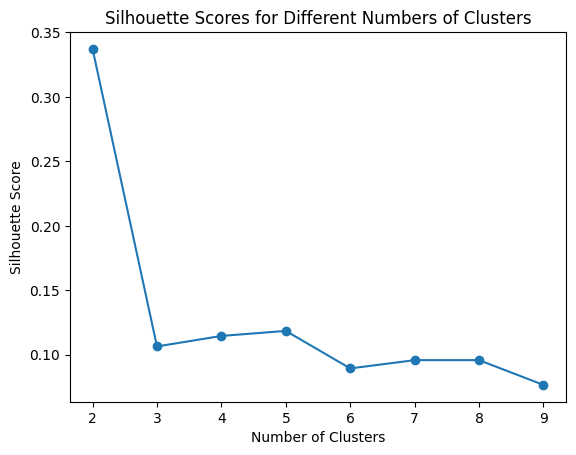

The best number of clusters is: 2


In [192]:
sil_scores = []
range_clusters = range(2, 10)

for n_clusters in range_clusters:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans.fit(scaled_data)
    cluster_labels = kmeans.labels_

    score = silhouette_score(scaled_data, cluster_labels)
    sil_scores.append(score)

plt.plot(range_clusters, sil_scores, marker='o')
plt.title('Silhouette Scores for Different Numbers of Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.show()

best_n_clusters = range_clusters[np.argmax(sil_scores)]
print(f"The best number of clusters is: {best_n_clusters}")

### n_clusters = 2

In [193]:
kmeans2 = KMeans(n_clusters=2, random_state=42)
kmeans2.fit(scaled_data)

KMeans(n_clusters=2, random_state=42)

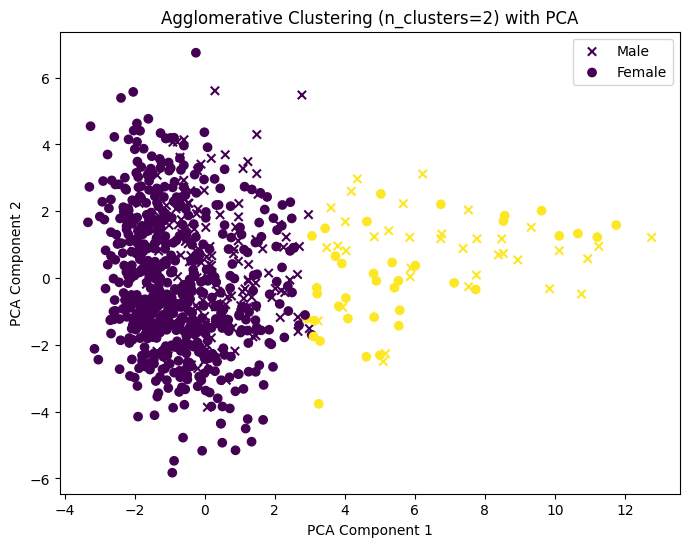

In [194]:
import numpy as np
import matplotlib.pyplot as plt

# Convert gender column to NumPy array to ensure proper indexing
gender = data["gender"].to_numpy()

plt.figure(figsize=(8, 6))

plt.scatter(X_pca[gender == 0, 0], X_pca[gender == 0, 1], 
            c=kmeans2.labels_[gender == 0], cmap='viridis', marker='x', label="Male")

plt.scatter(X_pca[gender == 1, 0], X_pca[gender == 1, 1], 
            c=kmeans2.labels_[gender == 1], cmap='viridis', marker='o', label="Female")

plt.title('Agglomerative Clustering (n_clusters=2) with PCA')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend()
plt.show()


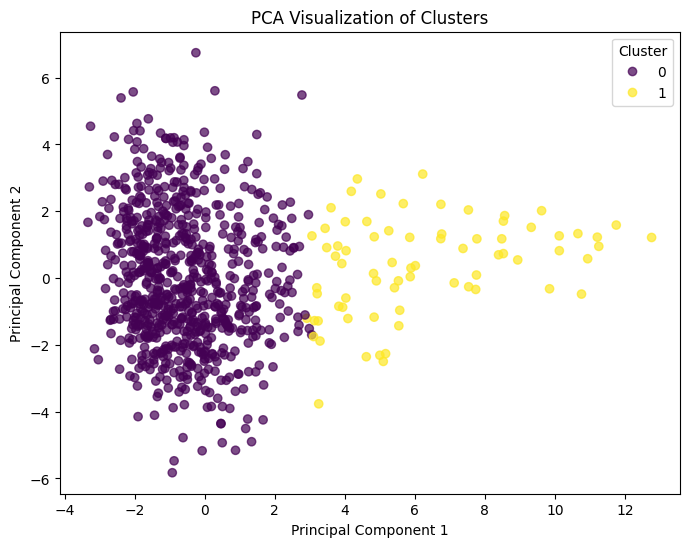

In [195]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans2.labels_, cmap='viridis', alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Clusters")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.show()

In [196]:
def analyze_clusters(data, kmeans_labels):
    data['cluster'] = kmeans_labels

    gender_counts = data.groupby(['cluster', 'gender']).size().unstack(fill_value=0)
    numeric_data = data.select_dtypes(include=[np.number])
    feature_means = numeric_data.groupby(data['cluster']).mean()

    print(gender_counts)
    print("energy",feature_means['energy'])

    feature_diffs = feature_means.diff().iloc[-1].abs()
    most_diff_feature = feature_diffs.idxmax()
    print(f"The feature with the most difference between clusters is: {most_diff_feature} with difference:", feature_diffs.max()) 
    for cluster in range(len(np.unique(kmeans_labels))):
        print(f"Cluster {cluster} has {len(kmeans_labels[kmeans_labels == cluster])} samples")
        print(f"{most_diff_feature} for cluster {cluster} is {feature_means.loc[cluster, most_diff_feature]}")

analyze_clusters(data, kmeans2.labels_)

gender     0    1
cluster          
0        154  594
1         36   37
energy cluster
0    0.173242
1    0.147760
Name: energy, dtype: float64
The feature with the most difference between clusters is: spectral_centroid with difference: 3604.3928764478655
Cluster 0 has 748 samples
spectral_centroid for cluster 0 is 1572.5687536351766
Cluster 1 has 73 samples
spectral_centroid for cluster 1 is 5176.961630083042


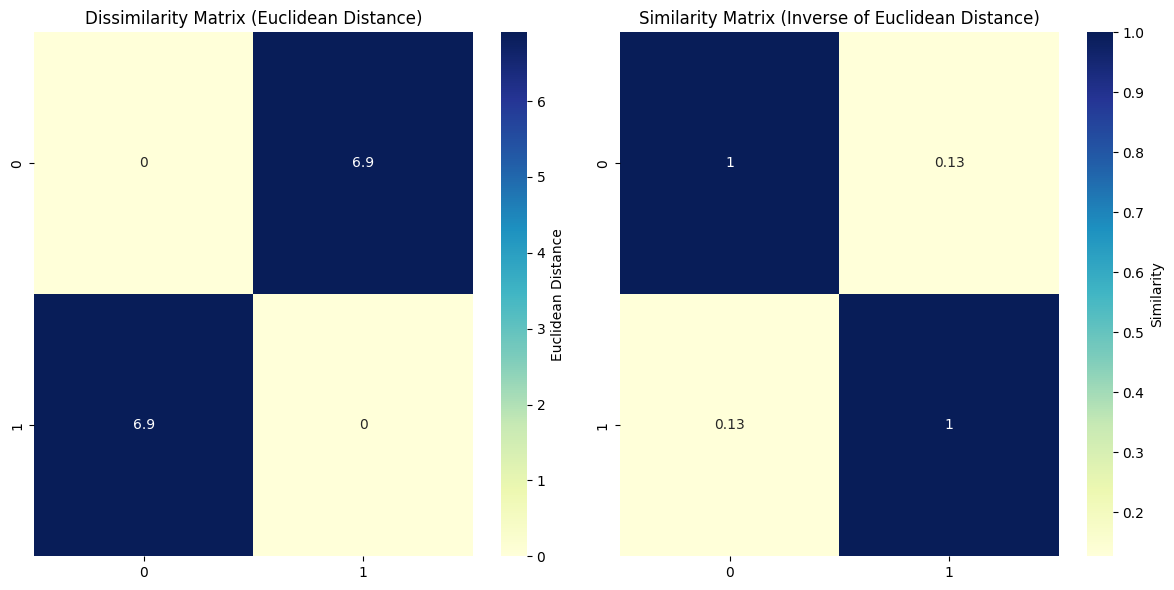


Min and Max Dissimilarity:
Min: 0.0 | Max: 6.905638640360468

Min and Max Similarity:
Min: 0.12649199457393914 | Max: 1.0


In [197]:
similarity_and_dissimilarity_report(kmeans2)

### n_clusters = 4

In [198]:
kmeans4 = KMeans(n_clusters=4, random_state=42)
kmeans4.fit(scaled_data)

KMeans(n_clusters=4, random_state=42)

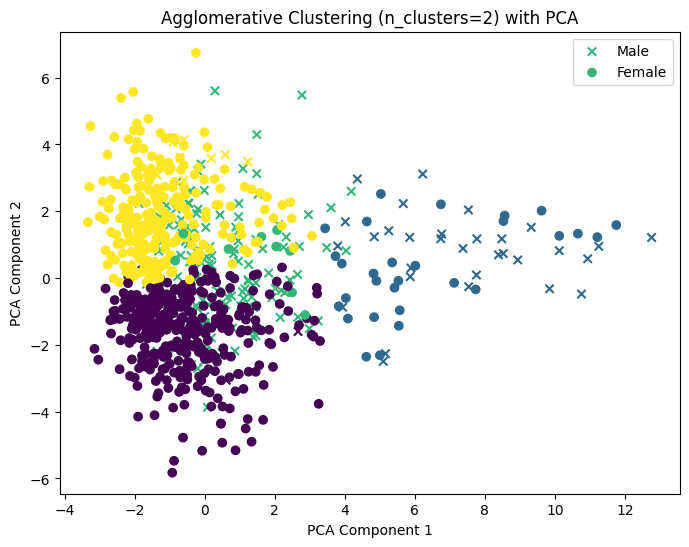

In [199]:
import numpy as np
import matplotlib.pyplot as plt

# Convert gender column to NumPy array to ensure proper indexing
gender = data["gender"].to_numpy()

plt.figure(figsize=(8, 6))

plt.scatter(X_pca[gender == 0, 0], X_pca[gender == 0, 1], 
            c=kmeans4.labels_[gender == 0], cmap='viridis', marker='x', label="Male")

plt.scatter(X_pca[gender == 1, 0], X_pca[gender == 1, 1], 
            c=kmeans4.labels_[gender == 1], cmap='viridis', marker='o', label="Female")

plt.title('Agglomerative Clustering (n_clusters=2) with PCA')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend()
plt.show()


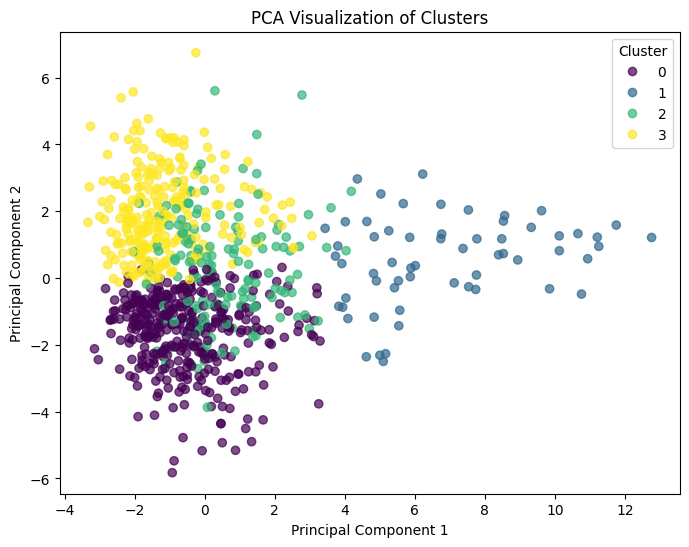

In [200]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans4.labels_, cmap='viridis', alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Clusters")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.show()

In [201]:
analyze_clusters(data, kmeans4.labels_)

gender     0    1
cluster          
0          2  345
1         31   29
2        147    9
3         10  248
energy cluster
0    0.171933
1    0.148860
2    0.174511
3    0.172696
Name: energy, dtype: float64
The feature with the most difference between clusters is: spectral_bandwidth with difference: 456.9081901420668
Cluster 0 has 347 samples
spectral_bandwidth for cluster 0 is 1824.1980345534444
Cluster 1 has 60 samples
spectral_bandwidth for cluster 1 is 2483.0703519336034
Cluster 2 has 156 samples
spectral_bandwidth for cluster 2 is 2221.4423766140653
Cluster 3 has 258 samples
spectral_bandwidth for cluster 3 is 1764.5341864719985


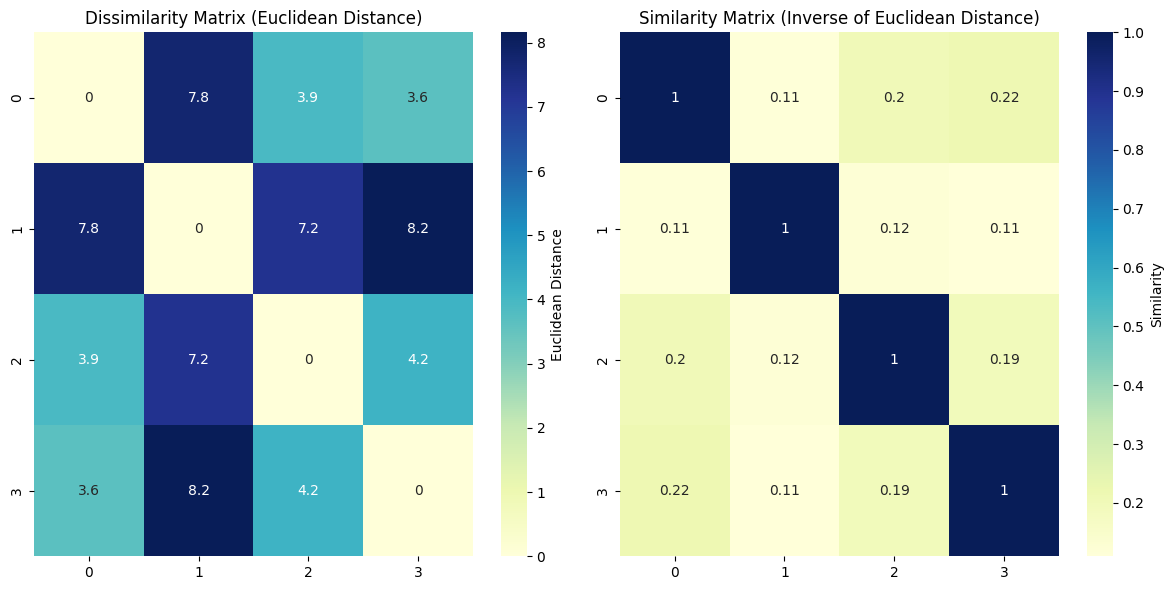


Min and Max Dissimilarity:
Min: 0.0 | Max: 8.159921708966866

Min and Max Similarity:
Min: 0.10917123876954932 | Max: 1.0


In [202]:
similarity_and_dissimilarity_report(kmeans4)

### n_clusters = 7

In [203]:
kmeans7 = KMeans(n_clusters=7, random_state=42)
kmeans7.fit(scaled_data)

KMeans(n_clusters=7, random_state=42)

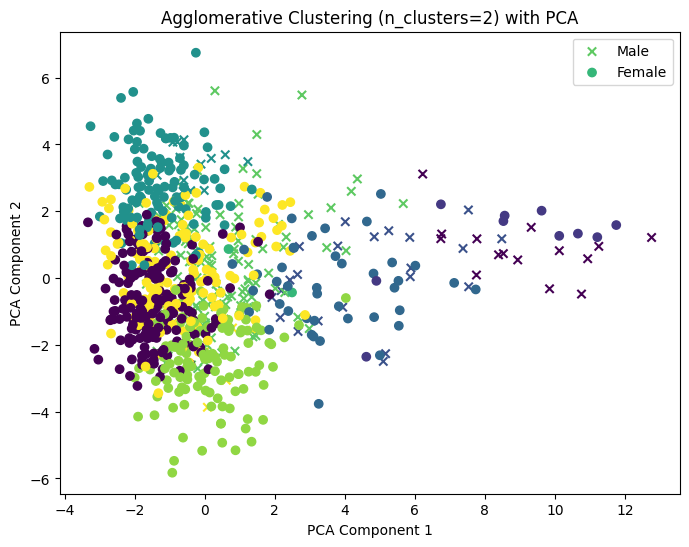

In [204]:
import numpy as np
import matplotlib.pyplot as plt

# Convert gender column to NumPy array to ensure proper indexing
gender = data["gender"].to_numpy()

plt.figure(figsize=(8, 6))

plt.scatter(X_pca[gender == 0, 0], X_pca[gender == 0, 1], 
            c=kmeans7.labels_[gender == 0], cmap='viridis', marker='x', label="Male")

plt.scatter(X_pca[gender == 1, 0], X_pca[gender == 1, 1], 
            c=kmeans7.labels_[gender == 1], cmap='viridis', marker='o', label="Female")

plt.title('Agglomerative Clustering (n_clusters=2) with PCA')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend()
plt.show()


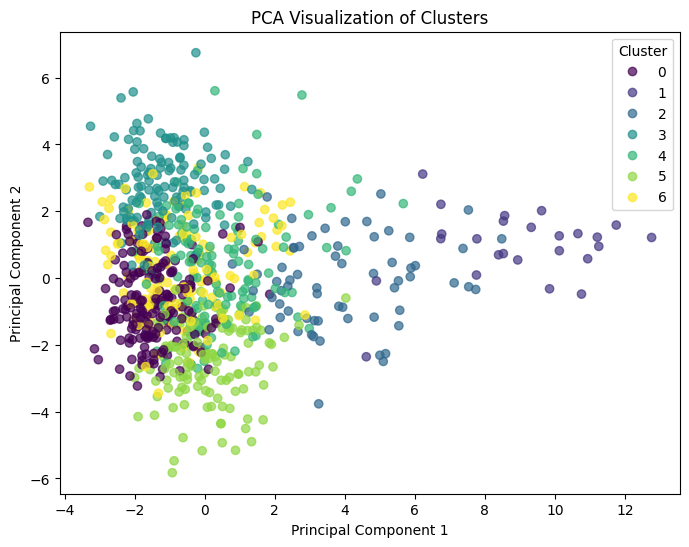

In [205]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans7.labels_, cmap='viridis', alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Clusters")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.show()

In [206]:
analyze_clusters(data, kmeans7.labels_)

gender     0    1
cluster          
0          0  192
1         15   10
2         22   42
3         14  114
4        134    2
5          5  127
6          0  144
energy cluster
0    0.174554
1    0.163887
2    0.144215
3    0.171141
4    0.174465
5    0.176536
6    0.170794
Name: energy, dtype: float64
The feature with the most difference between clusters is: spectral_centroid with difference: 405.1554611704064
Cluster 0 has 192 samples
spectral_centroid for cluster 0 is 1296.7246992356934
Cluster 1 has 25 samples
spectral_centroid for cluster 1 is 7292.492368234308
Cluster 2 has 64 samples
spectral_centroid for cluster 2 is 3517.480235541899
Cluster 3 has 128 samples
spectral_centroid for cluster 3 is 1528.5404499974745
Cluster 4 has 136 samples
spectral_centroid for cluster 4 is 1923.2300072716503
Cluster 5 has 132 samples
spectral_centroid for cluster 5 is 1384.936939073269
Cluster 6 has 144 samples
spectral_centroid for cluster 6 is 1790.0924002436755


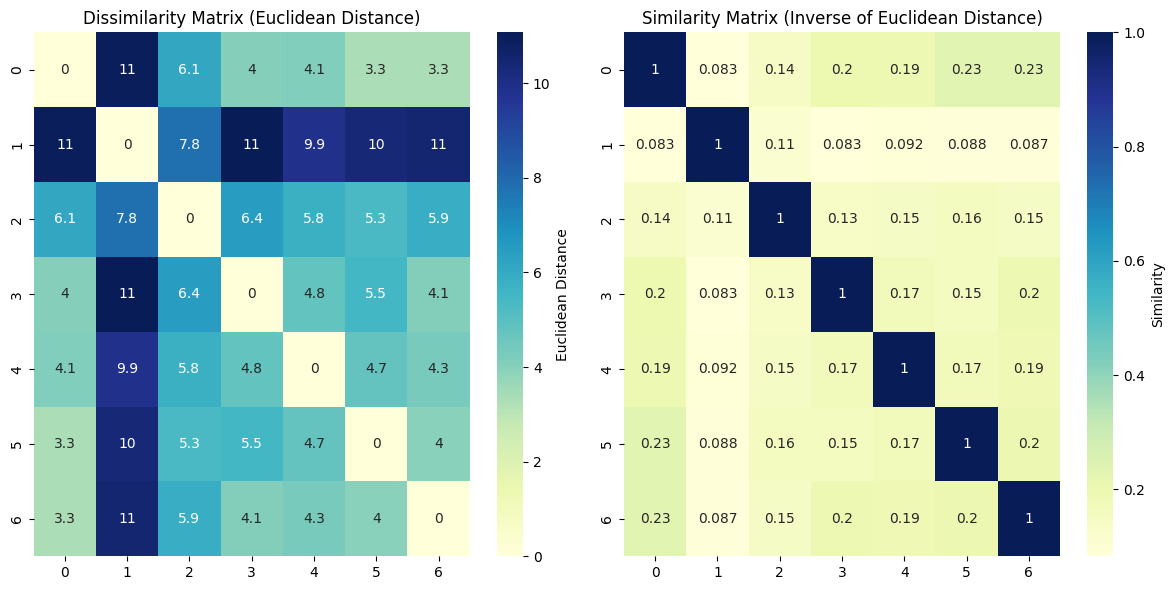


Min and Max Dissimilarity:
Min: 0.0 | Max: 11.077662221132504

Min and Max Similarity:
Min: 0.08279748031454977 | Max: 1.0


In [207]:
similarity_and_dissimilarity_report(kmeans7)

## Agglomerative Clustering

In [208]:
# def similarity_and_dissimilarity_report(agg_model: AgglomerativeClustering, data: np.ndarray):
#     if not hasattr(agg_model, 'labels_'):
#         raise ValueError("AgglomerativeClustering model must be fitted before calling this function.")

#     labels = agg_model.labels_
#     num_clusters = len(np.unique(labels))

#     dissimilarity_matrix = np.zeros((num_clusters, num_clusters))

#     for i in range(num_clusters):
#         for j in range(num_clusters):
#             if i != j:
#                 cluster_i = data[labels == i]
#                 cluster_j = data[labels == j]
#                 # Compute pairwise distance between two clusters (all pairs from cluster_i and cluster_j)
#                 dissimilarity_matrix[i, j] = np.mean(pdist(np.vstack([cluster_i, cluster_j])))

#     # Similarity is the inverse of dissimilarity
#     similarity_matrix = 1 / (1 + dissimilarity_matrix)

#     print("Dissimilarity Matrix (Mean Pairwise Distance):")
#     print(dissimilarity_matrix)

#     print("\nSimilarity Matrix (Inverse of Mean Pairwise Distance):")
#     print(similarity_matrix)

#     print("\nMin and Max Dissimilarity:")
#     print(f"Min: {np.min(dissimilarity_matrix[dissimilarity_matrix > 0])} | Max: {np.max(dissimilarity_matrix)}")

#     print("\nMin and Max Similarity:")
#     print(f"Min: {np.min(similarity_matrix[similarity_matrix > 0])} | Max: {np.max(similarity_matrix)}")

In [209]:
# def similarity_and_dissimilarity_report(kmeans_model: KMeans):
#     centroids = kmeans_model.cluster_centers_
#     num_clusters = len(centroids)
#     dissimilarity_matrix = euclidean_distances(centroids)
#     similarity_matrix = 1 / (1 + dissimilarity_matrix)

#     fig, ax = plt.subplots(1, 2, figsize=(12, 6))

#     sns.heatmap(dissimilarity_matrix, annot=True, cmap='YlGnBu', ax=ax[0], cbar_kws={'label': 'Euclidean Distance'})
#     ax[0].set_title("Dissimilarity Matrix (Euclidean Distance)")

#     sns.heatmap(similarity_matrix, annot=True, cmap='YlGnBu', ax=ax[1], cbar_kws={'label': 'Similarity'})
#     ax[1].set_title("Similarity Matrix (Inverse of Euclidean Distance)")

#     plt.tight_layout()
#     plt.show()

#     print("\nMin and Max Dissimilarity:")
#     print(f"Min: {np.min(dissimilarity_matrix)} | Max: {np.max(dissimilarity_matrix)}")

#     print("\nMin and Max Similarity:")
#     print(f"Min: {np.min(similarity_matrix)} | Max: {np.max(similarity_matrix)}")
    
def similarity_and_dissimilarity_report(agg_model: AgglomerativeClustering, data: np.ndarray):
    if not hasattr(agg_model, 'labels_'):
        raise ValueError("AgglomerativeClustering model must be fitted before calling this function.")
    labels = agg_model.labels_
    num_clusters = len(np.unique(labels))
    dissimilarity_matrix = np.zeros((num_clusters, num_clusters))
    for i in range(num_clusters):
        for j in range(num_clusters):
            if i != j:
                cluster_i = data[labels == i]
                cluster_j = data[labels == j]
                dissimilarity_matrix[i, j] = np.mean(pdist(np.vstack([cluster_i, cluster_j])))
    similarity_matrix = 1 / (1 + dissimilarity_matrix)
    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    sns.heatmap(dissimilarity_matrix, annot=True, cmap='YlGnBu', ax=ax[0], cbar_kws={'label': 'Mean Pairwise Distance'})
    ax[0].set_title("Dissimilarity Matrix (Mean Pairwise Distance)")
    sns.heatmap(similarity_matrix, annot=True, cmap='YlGnBu', ax=ax[1], cbar_kws={'label': 'Similarity'})
    ax[1].set_title("Similarity Matrix (Inverse of Mean Pairwise Distance)")
    plt.tight_layout()
    plt.show()
    print("\nMin and Max Dissimilarity:")
    print(f"Min: {np.min(dissimilarity_matrix[dissimilarity_matrix > 0])} | Max: {np.max(dissimilarity_matrix)}")
    print("\nMin and Max Similarity:")
    print(f"Min: {np.min(similarity_matrix[similarity_matrix > 0])} | Max: {np.max(similarity_matrix)}")

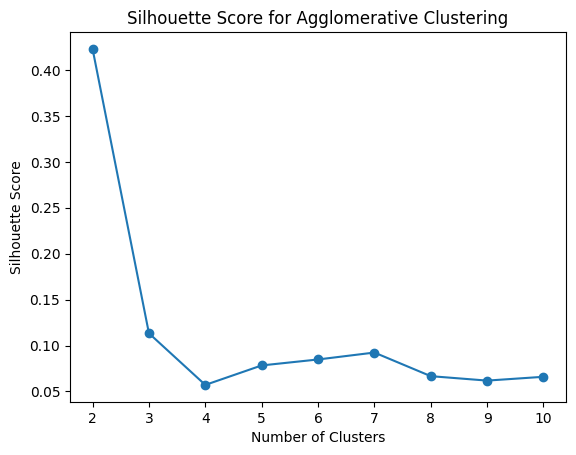

Best number of clusters based on Silhouette Score: 2


In [210]:
cluster_range = range(2, 11)
sil_scores = []

for n_clusters in cluster_range:
    agg_clustering = AgglomerativeClustering(n_clusters=n_clusters)
    agg_labels = agg_clustering.fit_predict(scaled_data)
    sil_score = silhouette_score(scaled_data, agg_labels)
    sil_scores.append(sil_score)

plt.plot(cluster_range, sil_scores, marker='o')
plt.title('Silhouette Score for Agglomerative Clustering')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.show()

best_k = cluster_range[sil_scores.index(max(sil_scores))]
print(f'Best number of clusters based on Silhouette Score: {best_k}')

### n_cluster = 2

In [211]:
agg_clustering2 = AgglomerativeClustering(n_clusters=2)
agg_labels2 = agg_clustering2.fit_predict(scaled_data)

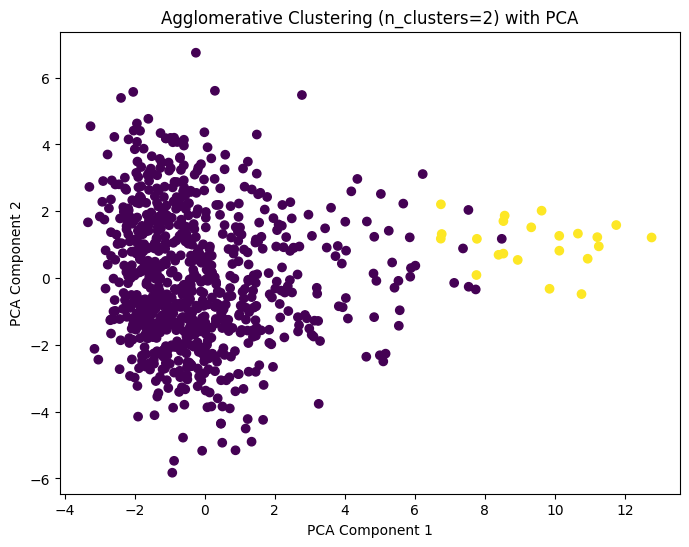

In [212]:
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=agg_labels2, cmap='viridis', marker='o')
plt.title(f'Agglomerative Clustering (n_clusters=2) with PCA')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()

In [213]:
analyze_clusters(data, agg_labels2)

gender     0    1
cluster          
0        176  623
1         14    8
energy cluster
0    0.171153
1    0.164556
Name: energy, dtype: float64
The feature with the most difference between clusters is: spectral_centroid with difference: 5822.969422795455
Cluster 0 has 799 samples
spectral_centroid for cluster 0 is 1737.0210711494205
Cluster 1 has 22 samples
spectral_centroid for cluster 1 is 7559.990493944875


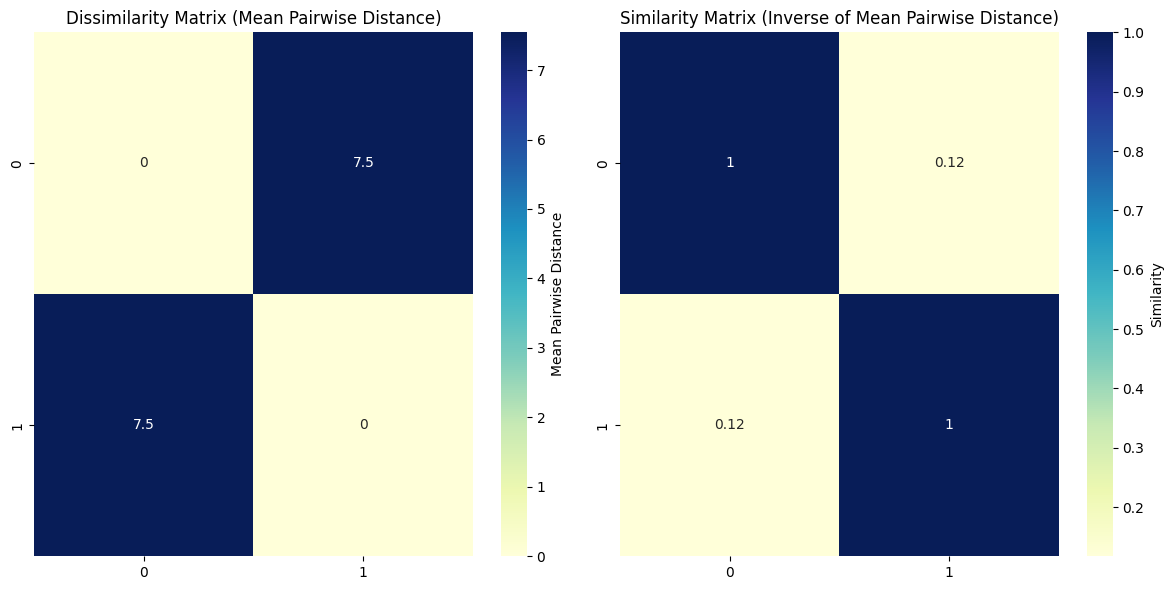


Min and Max Dissimilarity:
Min: 7.54340671653724 | Max: 7.54340671653724

Min and Max Similarity:
Min: 0.11704932624409968 | Max: 1.0


In [214]:
similarity_and_dissimilarity_report(agg_clustering2, scaled_data)

### n_cluster = 4

In [215]:
agg_clustering4 = AgglomerativeClustering(n_clusters=4)
agg_labels4 = agg_clustering4.fit_predict(scaled_data)

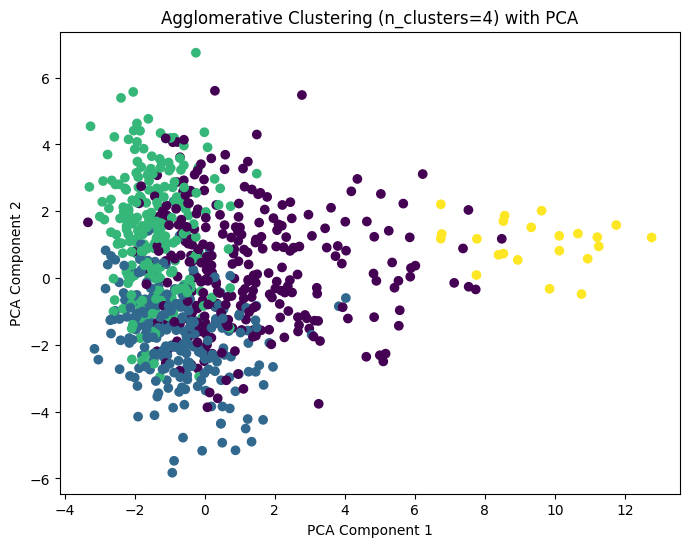

In [216]:
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=agg_labels4, cmap='viridis', marker='o')
plt.title(f'Agglomerative Clustering (n_clusters=4) with PCA')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()

In [217]:
analyze_clusters(data, agg_labels4)

gender     0    1
cluster          
0        175  122
1          0  255
2          1  246
3         14    8
energy cluster
0    0.162893
1    0.174943
2    0.177173
3    0.164556
Name: energy, dtype: float64
The feature with the most difference between clusters is: spectral_centroid with difference: 6136.1367166897635
Cluster 0 has 297 samples
spectral_centroid for cluster 0 is 2312.0644171638514
Cluster 1 has 255 samples
spectral_centroid for cluster 1 is 1370.6071410537668
Cluster 2 has 247 samples
spectral_centroid for cluster 2 is 1423.8537772551113
Cluster 3 has 22 samples
spectral_centroid for cluster 3 is 7559.990493944875


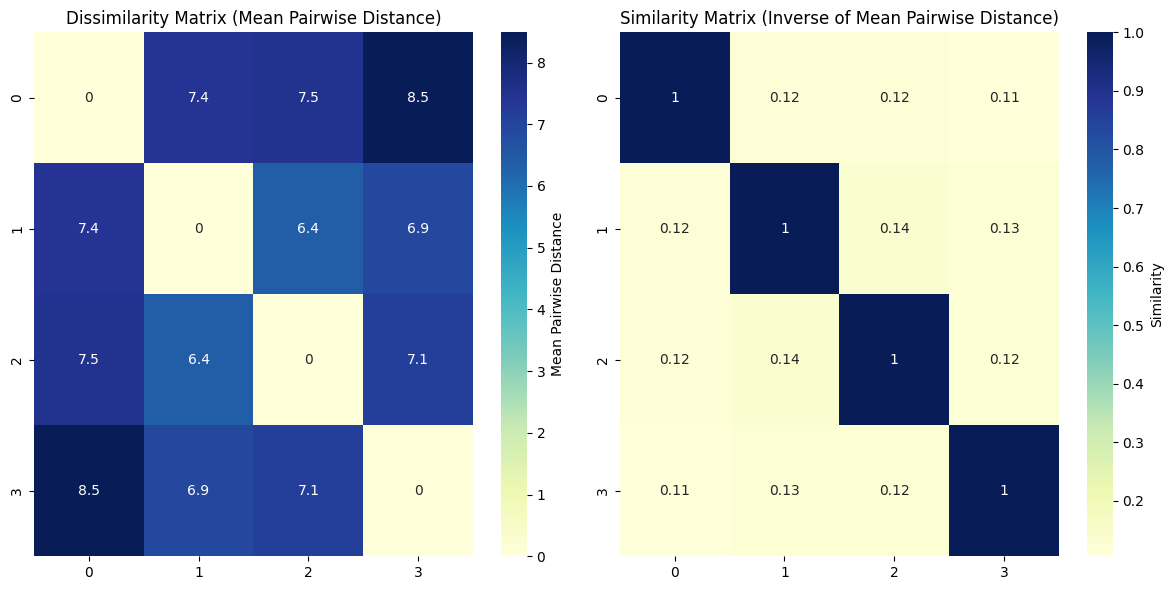


Min and Max Dissimilarity:
Min: 6.376515669195792 | Max: 8.489794911360578

Min and Max Similarity:
Min: 0.10537635526800096 | Max: 1.0


In [218]:
similarity_and_dissimilarity_report(agg_clustering4, scaled_data)

### n_cluster = 7

In [219]:
agg_clustering7 = AgglomerativeClustering(n_clusters=7)
agg_labels7 = agg_clustering7.fit_predict(scaled_data)

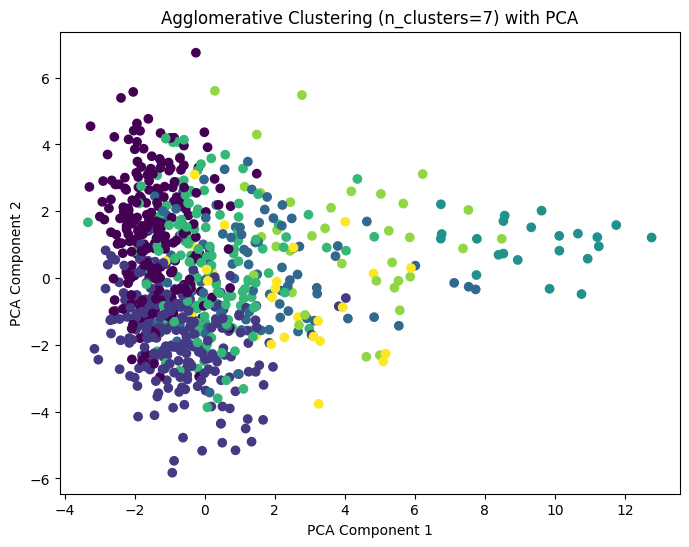

In [220]:
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=agg_labels7, cmap='viridis', marker='o')
plt.title(f'Agglomerative Clustering (n_clusters=7) with PCA')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()

In [221]:
analyze_clusters(data, agg_labels7)

gender     0    1
cluster          
0          1  246
1          0  255
2         14   71
3         14    8
4        137   12
5         13   22
6         11   17
energy cluster
0    0.177173
1    0.174943
2    0.166226
3    0.164556
4    0.177010
5    0.161216
6    0.079749
Name: energy, dtype: float64
The feature with the most difference between clusters is: spectral_centroid with difference: 2156.276261407741
Cluster 0 has 247 samples
spectral_centroid for cluster 0 is 1423.8537772551113
Cluster 1 has 255 samples
spectral_centroid for cluster 1 is 1370.6071410537668
Cluster 2 has 85 samples
spectral_centroid for cluster 2 is 2530.315491085534
Cluster 3 has 22 samples
spectral_centroid for cluster 3 is 7559.990493944875
Cluster 4 has 149 samples
spectral_centroid for cluster 4 is 1795.0634359565784
Cluster 5 has 35 samples
spectral_centroid for cluster 5 is 4198.692039956828
Cluster 6 has 28 samples
spectral_centroid for cluster 6 is 2042.4157785490872


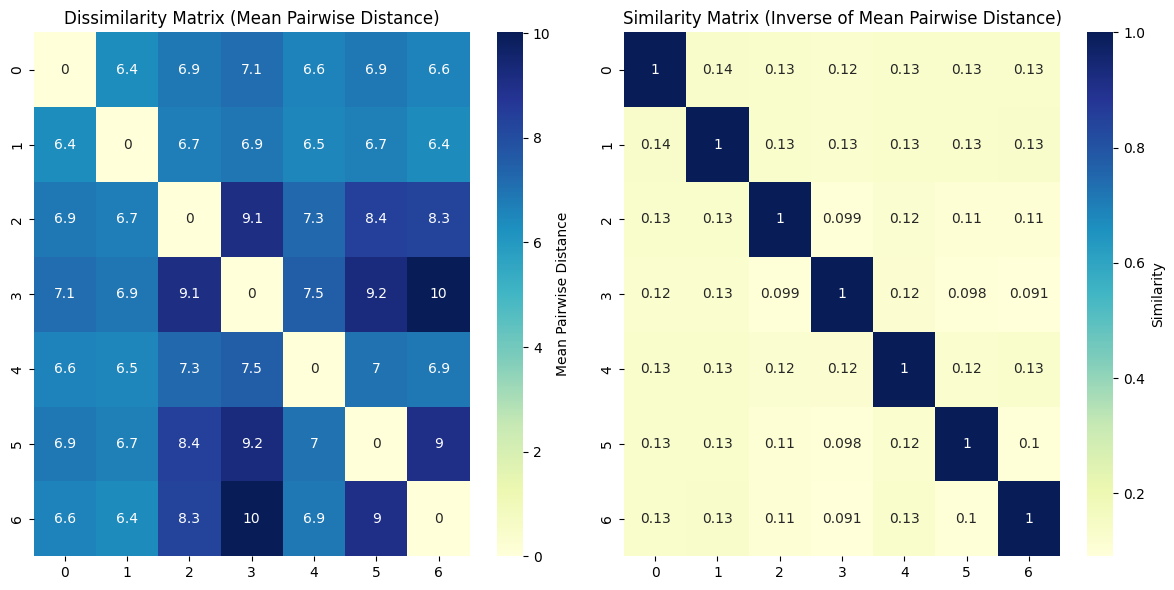


Min and Max Dissimilarity:
Min: 6.376515669195792 | Max: 10.017054270800887

Min and Max Similarity:
Min: 0.09076836470256443 | Max: 1.0


In [222]:
similarity_and_dissimilarity_report(agg_clustering7, scaled_data)

# DBscan

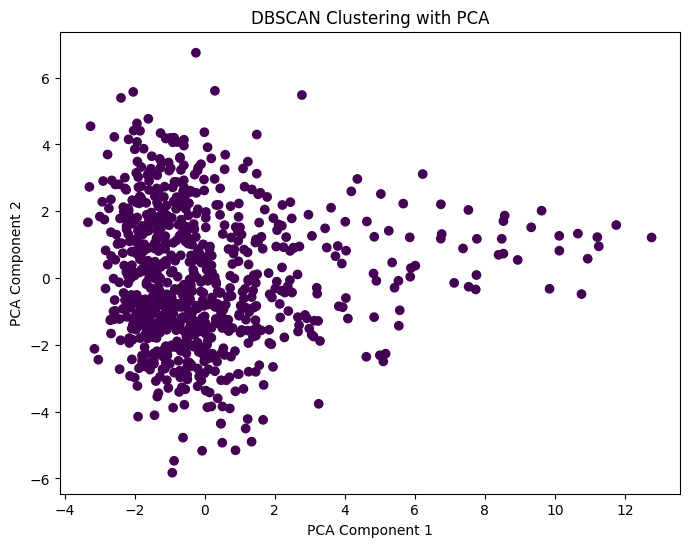

In [223]:
dbscan = DBSCAN(eps=0.5, min_samples=5)

dbscan_labels = dbscan.fit_predict(scaled_data)

# Plot the clusters
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, cmap='viridis', marker='o')
plt.title('DBSCAN Clustering with PCA')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()